# Advanced Cluster-Based Predictive Models - Ebro River Basin

This notebook implements advanced machine learning and time series models for discharge prediction, **trained separately for each cluster** identified in the clustering analysis.

## Objectives

1. Train cluster-specific models using various algorithms:
   - **Neural Networks** (MLP and Deep Learning)
   - **Advanced Tree Models** (XGBoost, LightGBM, CatBoost)
   - **LSTM Networks** for time series prediction
   - **ARIMA/SARIMAX** for time series forecasting
2. Compare model performance across clusters
3. Identify which models work best for each cluster
4. Predict river discharge (qav) based on climate variables (Hr, Tª, P, soil_moisture, etc.)

## Imports and Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import json
import os
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Traditional ML
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Advanced tree models
try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost not available. Install with: pip install xgboost")

try:
    import lightgbm as lgb
    LIGHTGBM_AVAILABLE = True
except ImportError:
    LIGHTGBM_AVAILABLE = False
    print("LightGBM not available. Install with: pip install lightgbm")

try:
    from catboost import CatBoostRegressor
    CATBOOST_AVAILABLE = True
except ImportError:
    CATBOOST_AVAILABLE = False
    print("CatBoost not available. Install with: pip install catboost")

# Deep Learning
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers, Sequential
    from tensorflow.keras.callbacks import EarlyStopping
    TENSORFLOW_AVAILABLE = True
except ImportError:
    TENSORFLOW_AVAILABLE = False
    print("TensorFlow not available. Install with: pip install tensorflow")

# Time series models
try:
    from statsmodels.tsa.arima.model import ARIMA
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    from statsmodels.tsa.stattools import adfuller
    STATSMODELS_AVAILABLE = True
except ImportError:
    STATSMODELS_AVAILABLE = False
    print("Statsmodels not available. Install with: pip install statsmodels")

print("\nLibrary Availability:")
print(f"  XGBoost: {XGBOOST_AVAILABLE}")
print(f"  LightGBM: {LIGHTGBM_AVAILABLE}")
print(f"  CatBoost: {CATBOOST_AVAILABLE}")
print(f"  TensorFlow: {TENSORFLOW_AVAILABLE}")
print(f"  Statsmodels: {STATSMODELS_AVAILABLE}")


Library Availability:
  XGBoost: True
  LightGBM: True
  CatBoost: True
  TensorFlow: True
  Statsmodels: True


## Load Cleaned Data and Cluster Assignments

In [2]:
# Load merged data
base_path = "../../data/clean/merged_data/"

join_dict = {}
for filename in os.listdir(base_path):
    if filename.endswith(".json"):
        basin_name = os.path.splitext(filename)[0]
        df = pd.read_json(os.path.join(base_path, filename), orient="records")
        # Convert Date to datetime
        df['Date'] = pd.to_datetime(df['Date'])
        df = df.sort_values('Date').reset_index(drop=True)
        join_dict[basin_name] = df

print(f"Loaded data for {len(join_dict)} basins")
print(list(join_dict.keys()))

Loaded data for 20 basins
['Deza', 'Larraun', 'Flamisell', 'Zidacos', 'Subialde', 'Zatoya', 'Yanguas', 'Vallfarrera', 'Anduña', 'Isuela', 'Urrobi', 'Bailin', 'Oroncillo', 'Trueba', 'Sangüesa', 'Tiron', 'Rudron', 'Nela', 'Garona', 'Ubagua']


## 📊 Datos SMAP Integrados

**Actualización**: El dataset ahora incluye datos de SMAP (Soil Moisture Active Passive) de la NASA.

### Nuevas Variables (10 columnas):

**Humedad del Suelo - Zona Radicular**:
- `sm_rootzone_av` - Promedio
- `sm_rootzone_dif` - Diferencia
- `sm_rootzone_max` - Máximo
- `sm_rootzone_min` - Mínimo

**Humedad del Suelo - Superficie**:
- `sm_surface_av` - Promedio
- `sm_surface_dif` - Diferencia
- `sm_surface_max` - Máximo
- `sm_surface_min` - Mínimo

**Caudales SMAP**:
- `q0_r` - Caudal zona radicular
- `q0_s` - Caudal superficial

Estas variables pueden mejorar significativamente los análisis y modelos predictivos.

In [3]:
# Verificar presencia de columnas SMAP
sample_basin = list(join_dict.keys())[0]
smap_cols = [col for col in join_dict[sample_basin].columns if 'sm_' in col or 'q0_' in col]

print(f"✅ Dataset cargado con {len(join_dict)} cuencas")
print(f"📊 Columnas totales: {len(join_dict[sample_basin].columns)}")
print(f"🎯 Columnas SMAP encontradas ({len(smap_cols)}): {smap_cols}")

if len(smap_cols) == 0:
    print("\n⚠️  WARNING: No se encontraron columnas SMAP.")
    print("   Asegúrate de ejecutar el notebook 0-ebro-data-cleaning.ipynb primero.")

✅ Dataset cargado con 20 cuencas
📊 Columnas totales: 73
🎯 Columnas SMAP encontradas (10): ['q0_r', 'q0_s', 'sm_rootzone_av', 'sm_rootzone_dif', 'sm_rootzone_max', 'sm_rootzone_min', 'sm_surface_av', 'sm_surface_dif', 'sm_surface_max', 'sm_surface_min']


In [4]:
# Cluster assignments from notebook 2-ebro-clustering.ipynb
cluster_assignments = {
    'Cluster_0': ['Deza', 'Flamisell', 'Zidacos', 'Subialde', 'Zatoya', 'Vallfarrera', 
                  'Anduña', 'Isuela', 'Urrobi', 'Oroncillo', 'Sangüesa', 'Tiron', 
                  'Rudron', 'Garona', 'Ubagua'],
    'Cluster_1': ['Bailin'],
    'Cluster_2': ['Larraun', 'Trueba', 'Nela']
}

# Create reverse mapping
basin_to_cluster = {}
for cluster_name, basins in cluster_assignments.items():
    for basin in basins:
        basin_to_cluster[basin] = cluster_name

print("Cluster assignments:")
for cluster, basins in cluster_assignments.items():
    print(f"  {cluster}: {len(basins)} basins")

Cluster assignments:
  Cluster_0: 15 basins
  Cluster_1: 1 basins
  Cluster_2: 3 basins


## Data Preparation for Cluster-Based Models

### Actualización: Features SMAP

**Nota**: Ahora puedes incluir variables SMAP en tus features para potencialmente mejorar el modelo:
- `sm_rootzone_av`, `sm_surface_av` (humedades promedio)
- `q0_r`, `q0_s` (caudales SMAP)

Ejemplo de features actualizado está comentado abajo.

In [5]:
# OPCIÓN: Features incluyendo SMAP
feature_cols_with_smap = [
    'P',              # Precipitation
    'soil_moisture',  # Original soil moisture
    'sm_rootzone_av', # SMAP root zone (NUEVO)
    'sm_surface_av',  # SMAP surface (NUEVO)
    'tav', 'tmax', 'tmin',
    'et0',
    'SolarRad',
    # Puedes agregar q0_r, q0_s también
]

# Verificar que existen
available_features = [f for f in feature_cols_with_smap if f in join_dict[list(join_dict.keys())[0]].columns]
print(f"Features disponibles con SMAP: {len(available_features)}/{len(feature_cols_with_smap)}")
print(f"Faltan: {set(feature_cols_with_smap) - set(available_features)}")

Features disponibles con SMAP: 9/9
Faltan: set()


In [6]:
# Define feature sets
# Using climate variables that correlate with discharge
feature_cols = [
    'P',              # Precipitation
    'soil_moisture',  # Soil moisture
    'tav', 'tmax', 'tmin',  # Temperature
    'Hrav', 'Hrmax',  # Humidity (note: Hrmin has missing values)
    'et0',            # Evapotranspiration
    'SolarRad',       # Solar radiation
    'wv', 'wvmax'     # Wind
]

target_col = 'qav'  # Average discharge

# Prepare cluster-specific datasets
cluster_data = {}

for cluster_name, basin_list in cluster_assignments.items():
    cluster_dfs = []
    
    for basin in basin_list:
        if basin in join_dict:
            df = join_dict[basin].copy()
            df['Basin'] = basin
            cluster_dfs.append(df)
    
    if cluster_dfs:
        combined_df = pd.concat(cluster_dfs, ignore_index=True)
        # Drop rows with missing values in key columns
        combined_df = combined_df.dropna(subset=feature_cols + [target_col])
        cluster_data[cluster_name] = combined_df
        
        print(f"{cluster_name}: {len(combined_df)} observations from {len(basin_list)} basins")
        print(f"  Date range: {combined_df['Date'].min()} to {combined_df['Date'].max()}")

Cluster_0: 42324 observations from 15 basins
  Date range: 2020-10-01 00:00:00 to 2025-09-30 00:00:00
Cluster_1: 3553 observations from 1 basins
  Date range: 2020-10-01 00:00:00 to 2025-09-30 00:00:00
Cluster_2: 10549 observations from 3 basins
  Date range: 2020-10-01 00:00:00 to 2025-09-30 00:00:00


## Helper Functions

In [7]:
def evaluate_model(y_true, y_pred, model_name="Model"):
    """
    Calculate performance metrics.
    """
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    return {
        'Model': model_name,
        'MSE': mse,
        'RMSE': rmse,
        'MAE': mae,
        'R²': r2
    }

def plot_predictions(y_true, y_pred, title="Predictions vs Actual", save_path=None):
    """
    Plot predicted vs actual values.
    """
    plt.figure(figsize=(8, 6))
    plt.scatter(y_true, y_pred, alpha=0.5)
    
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect prediction')
    
    plt.xlabel('Actual Values (m³/s)')
    plt.ylabel('Predicted Values (m³/s)')
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

def create_time_series_sequences(data, features, target, n_steps=7):
    """
    Create sequences for LSTM model.
    n_steps: number of previous timesteps to use
    """
    X, y = [], []
    for i in range(n_steps, len(data)):
        X.append(data[features].iloc[i-n_steps:i].values)
        y.append(data[target].iloc[i])
    return np.array(X), np.array(y)

# Part 1: Neural Network Models

Train neural networks for each cluster using scikit-learn's MLPRegressor.

NEURAL NETWORK MODELS (MLP)

Cluster_0
Training MLP (3 layers: 100-50-25)...

Test Set Performance:
  RMSE: 2.3188
  MAE: 1.2040
  R²: 0.2145


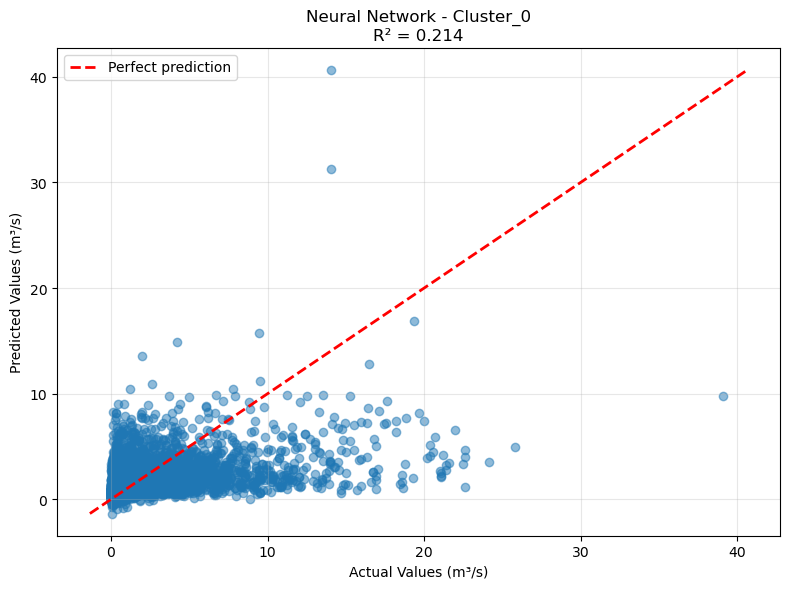


Cluster_1
Training MLP (3 layers: 100-50-25)...

Test Set Performance:
  RMSE: 0.0295
  MAE: 0.0200
  R²: 0.1685


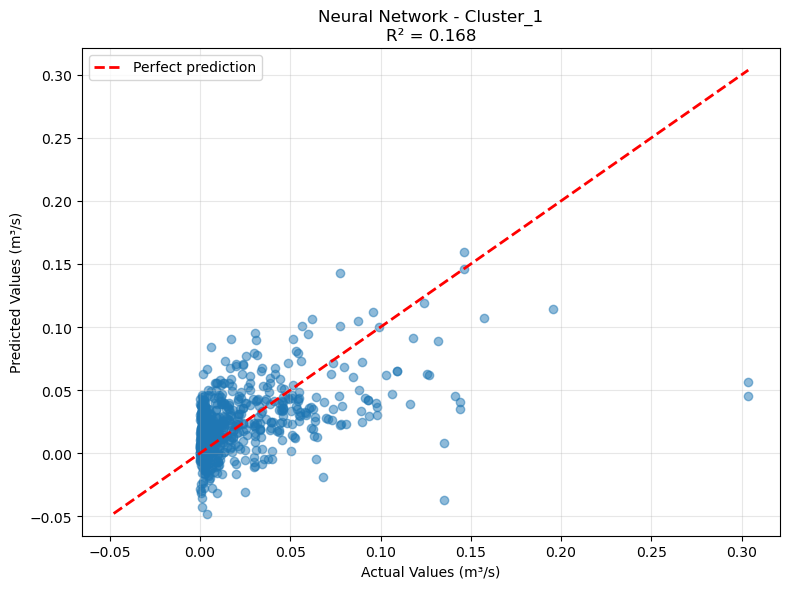


Cluster_2
Training MLP (3 layers: 100-50-25)...

Test Set Performance:
  RMSE: 8.2160
  MAE: 3.3151
  R²: 0.2220


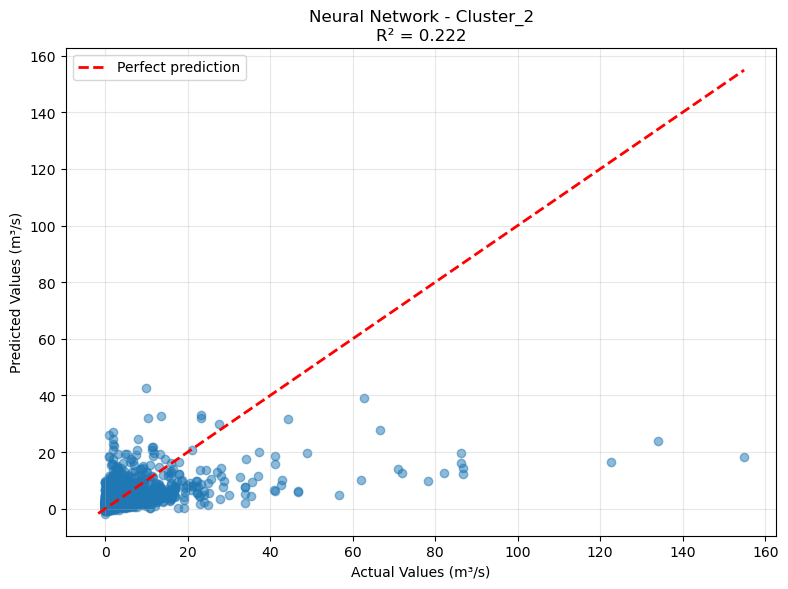


NEURAL NETWORK RESULTS SUMMARY


,Model,MSE,RMSE,MAE,R²
0,MLP-Cluster_0 (Train),4.868044,2.206365,1.159920,0.352233
1,MLP-Cluster_0 (Test),5.376676,2.318766,1.204040,0.214462
2,MLP-Cluster_1 (Train),0.000351,0.018741,0.012962,0.632545
3,MLP-Cluster_1 (Test),0.000872,0.029525,0.020025,0.168498
4,MLP-Cluster_2 (Train),47.035690,6.858257,2.923955,0.383924
5,MLP-Cluster_2 (Test),67.502005,8.215960,3.315142,0.221994


In [8]:
# Create output directory
os.makedirs("4.1-results/neural_networks", exist_ok=True)

nn_results = []

print("="*80)
print("NEURAL NETWORK MODELS (MLP)")
print("="*80)

for cluster_name, df in cluster_data.items():
    print(f"\n{'='*80}")
    print(f"{cluster_name}")
    print(f"{'='*80}")
    
    # Prepare data
    X = df[feature_cols].values
    y = df[target_col].values
    
    # Train/test split (80/20)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    
    # Scale features
    scaler_X = StandardScaler()
    X_train_scaled = scaler_X.fit_transform(X_train)
    X_test_scaled = scaler_X.transform(X_test)
    
    # Train MLP
    mlp = MLPRegressor(
        hidden_layer_sizes=(100, 50, 25),  # 3 hidden layers
        activation='relu',
        solver='adam',
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=42,
        verbose=False
    )
    
    print(f"Training MLP (3 layers: 100-50-25)...")
    mlp.fit(X_train_scaled, y_train)
    
    # Predictions
    y_train_pred = mlp.predict(X_train_scaled)
    y_test_pred = mlp.predict(X_test_scaled)
    
    # Evaluate
    train_metrics = evaluate_model(y_train, y_train_pred, f"MLP-{cluster_name} (Train)")
    test_metrics = evaluate_model(y_test, y_test_pred, f"MLP-{cluster_name} (Test)")
    
    nn_results.append(train_metrics)
    nn_results.append(test_metrics)
    
    print(f"\nTest Set Performance:")
    print(f"  RMSE: {test_metrics['RMSE']:.4f}")
    print(f"  MAE: {test_metrics['MAE']:.4f}")
    print(f"  R²: {test_metrics['R²']:.4f}")
    
    # Plot predictions
    plot_predictions(
        y_test, y_test_pred,
        f"Neural Network - {cluster_name}\nR² = {test_metrics['R²']:.3f}",
        f"4.1-results/neural_networks/{cluster_name}_mlp_predictions.png"
    )

# Summary
nn_results_df = pd.DataFrame(nn_results)
print("\n" + "="*80)
print("NEURAL NETWORK RESULTS SUMMARY")
print("="*80)
display(nn_results_df)

# Part 2: Advanced Tree-Based Models

Train XGBoost, LightGBM, and CatBoost for each cluster.

ADVANCED TREE-BASED MODELS

Cluster_0

Training Random Forest...
Training XGBoost...
Training LightGBM...
Training CatBoost...

Test Set Performance:
  Random Forest: R² = 0.4276, RMSE = 1.9793
  XGBoost: R² = 0.3723, RMSE = 2.0728
  LightGBM: R² = 0.3044, RMSE = 2.1820
  CatBoost: R² = 0.2536, RMSE = 2.2602


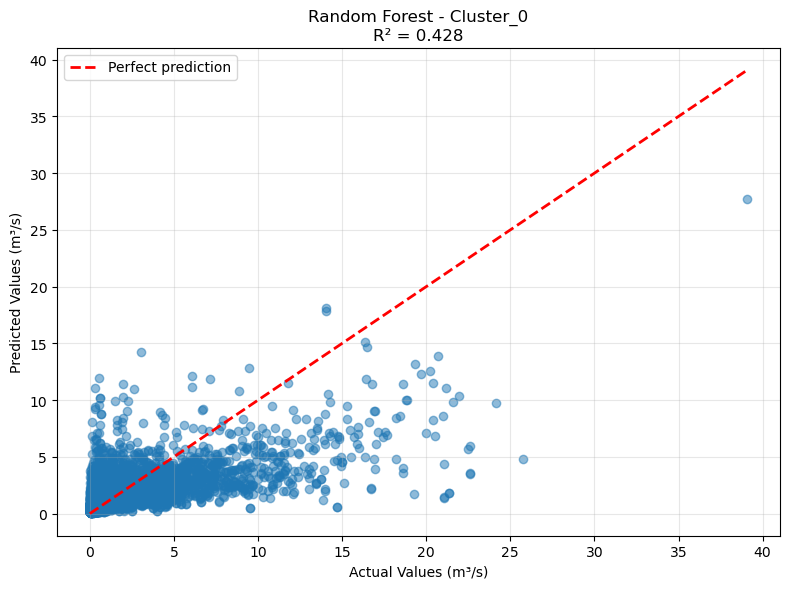


Cluster_1

Training Random Forest...
Training XGBoost...
Training LightGBM...
Training CatBoost...

Test Set Performance:
  Random Forest: R² = 0.5556, RMSE = 0.0216
  XGBoost: R² = 0.6480, RMSE = 0.0192
  LightGBM: R² = 0.5325, RMSE = 0.0221
  CatBoost: R² = 0.4512, RMSE = 0.0240


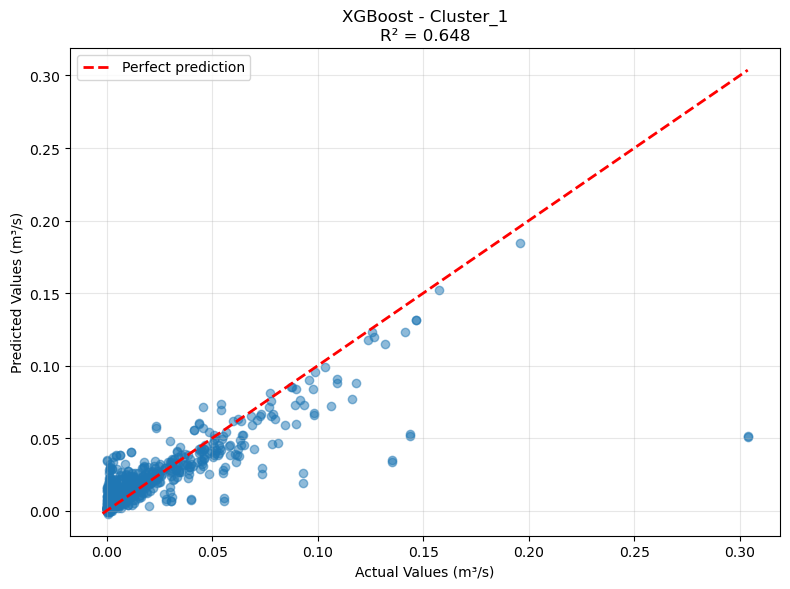


Cluster_2

Training Random Forest...
Training XGBoost...
Training LightGBM...
Training CatBoost...

Test Set Performance:
  Random Forest: R² = 0.6491, RMSE = 5.5174
  XGBoost: R² = 0.6045, RMSE = 5.8581
  LightGBM: R² = 0.5961, RMSE = 5.9198
  CatBoost: R² = 0.5381, RMSE = 6.3307


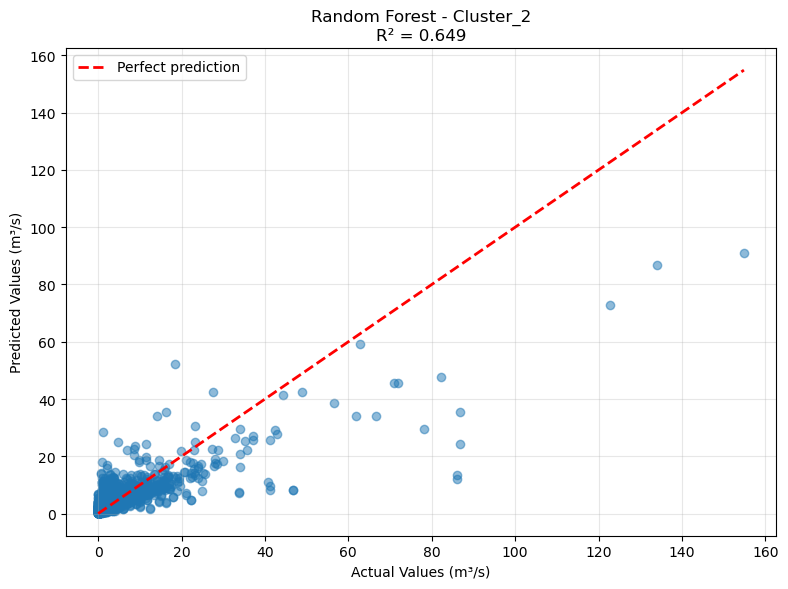


TREE MODELS RESULTS SUMMARY


,Model,MSE,RMSE,MAE,R²
0,Random Forest-Cluster_0 (Test),3.917812,1.979346,1.017915,0.427604
1,XGBoost-Cluster_0 (Test),4.296497,2.072799,1.078173,0.372278
2,LightGBM-Cluster_0 (Test),4.760941,2.181958,1.138805,0.304422
3,CatBoost-Cluster_0 (Test),5.108700,2.260243,1.187708,0.253614
4,Random Forest-Cluster_1 (Test),0.000466,0.021584,0.011413,0.555614
5,XGBoost-Cluster_1 (Test),0.000369,0.019211,0.008900,0.647950
6,LightGBM-Cluster_1 (Test),0.000490,0.022138,0.012384,0.532499
7,CatBoost-Cluster_1 (Test),0.000575,0.023987,0.013851,0.451165
8,Random Forest-Cluster_2 (Test),30.441984,5.517425,2.350773,0.649136
9,XGBoost-Cluster_2 (Test),34.317754,5.858136,2.280281,0.604465


In [9]:
os.makedirs("4.1-results/tree_models", exist_ok=True)

tree_results = []

print("="*80)
print("ADVANCED TREE-BASED MODELS")
print("="*80)

for cluster_name, df in cluster_data.items():
    print(f"\n{'='*80}")
    print(f"{cluster_name}")
    print(f"{'='*80}")
    
    # Prepare data
    X = df[feature_cols].values
    y = df[target_col].values
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    
    # Dictionary to store models and predictions
    models = {}
    
    # 1. Random Forest (baseline)
    print("\nTraining Random Forest...")
    rf_model = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
    rf_model.fit(X_train, y_train)
    models['Random Forest'] = rf_model
    
    # 2. XGBoost
    if XGBOOST_AVAILABLE:
        print("Training XGBoost...")
        xgb_model = xgb.XGBRegressor(
            n_estimators=200,
            max_depth=6,
            learning_rate=0.1,
            random_state=42,
            n_jobs=-1
        )
        xgb_model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)
        models['XGBoost'] = xgb_model
    
    # 3. LightGBM
    if LIGHTGBM_AVAILABLE:
        print("Training LightGBM...")
        lgb_model = lgb.LGBMRegressor(
            n_estimators=200,
            max_depth=6,
            learning_rate=0.1,
            random_state=42,
            n_jobs=-1,
            verbose=-1
        )
        lgb_model.fit(X_train, y_train)
        models['LightGBM'] = lgb_model
    
    # 4. CatBoost
    if CATBOOST_AVAILABLE:
        print("Training CatBoost...")
        cat_model = CatBoostRegressor(
            iterations=200,
            depth=6,
            learning_rate=0.1,
            random_state=42,
            verbose=False
        )
        cat_model.fit(X_train, y_train)
        models['CatBoost'] = cat_model
    
    # Evaluate all models
    print("\nTest Set Performance:")
    for model_name, model in models.items():
        y_pred = model.predict(X_test)
        metrics = evaluate_model(y_test, y_pred, f"{model_name}-{cluster_name} (Test)")
        tree_results.append(metrics)
        print(f"  {model_name}: R² = {metrics['R²']:.4f}, RMSE = {metrics['RMSE']:.4f}")
    
    # Plot best model
    best_model_name = max(models.keys(), key=lambda k: r2_score(y_test, models[k].predict(X_test)))
    best_pred = models[best_model_name].predict(X_test)
    best_r2 = r2_score(y_test, best_pred)
    
    plot_predictions(
        y_test, best_pred,
        f"{best_model_name} - {cluster_name}\nR² = {best_r2:.3f}",
        f"4.1-results/tree_models/{cluster_name}_{best_model_name.replace(' ', '_')}_predictions.png"
    )

# Summary
tree_results_df = pd.DataFrame(tree_results)
print("\n" + "="*80)
print("TREE MODELS RESULTS SUMMARY")
print("="*80)
display(tree_results_df)

# Part 3: LSTM Models for Time Series

Train LSTM networks to capture temporal dependencies in the data.

LSTM MODELS

Cluster_0
Created 42317 sequences (shape: (42317, 7, 11))

Training LSTM...

Test Set Performance:
  RMSE: 3.2943
  MAE: 1.6331
  R²: -0.0100


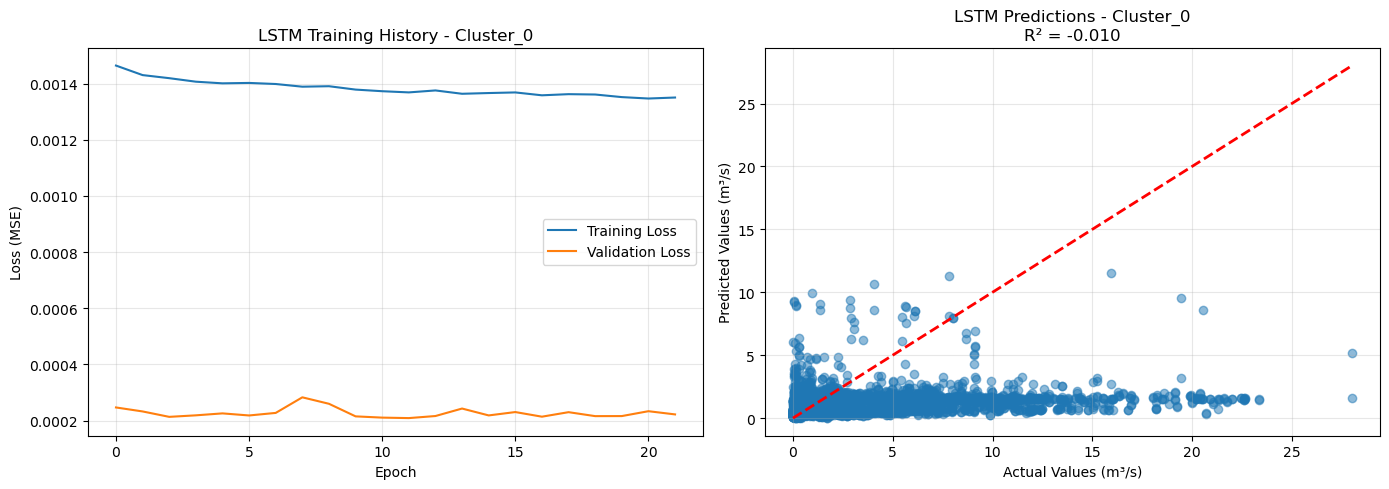


Cluster_1
Created 3546 sequences (shape: (3546, 7, 11))

Training LSTM...

Test Set Performance:
  RMSE: 0.0416
  MAE: 0.0261
  R²: -0.0822


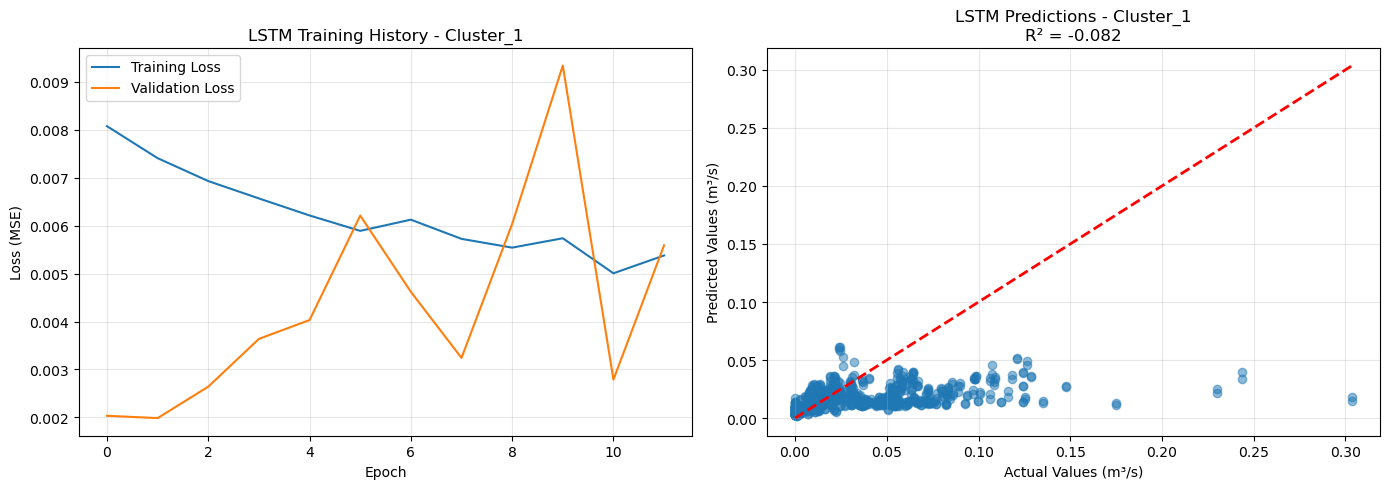


Cluster_2
Created 10542 sequences (shape: (10542, 7, 11))

Training LSTM...

Test Set Performance:
  RMSE: 5.4652
  MAE: 2.8662
  R²: 0.1657


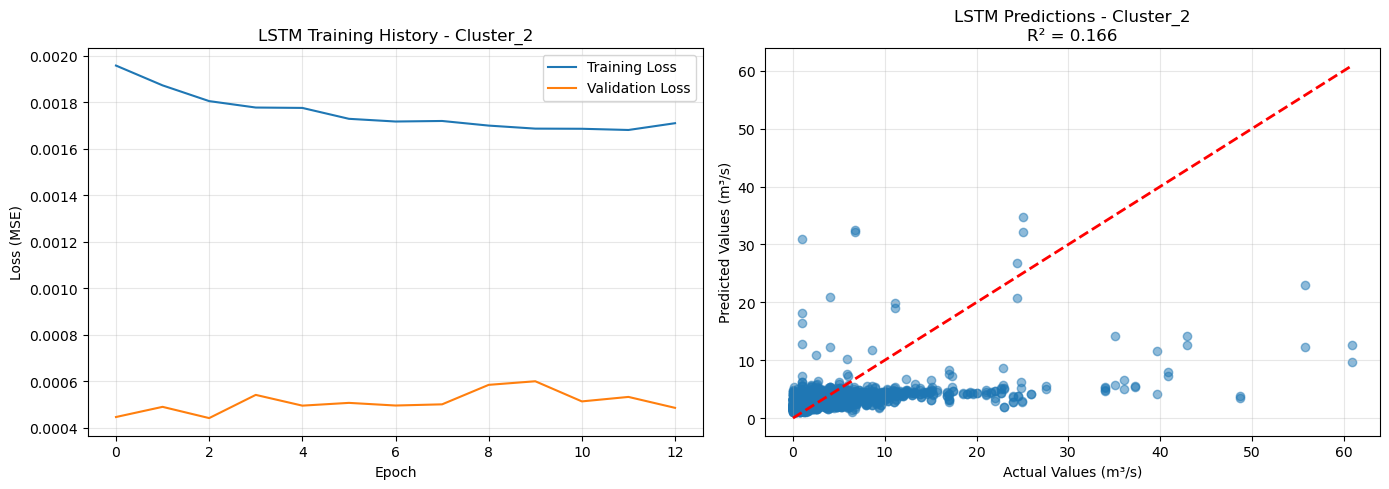


LSTM RESULTS SUMMARY


,Model,MSE,RMSE,MAE,R²
0,LSTM-Cluster_0 (Test),10.852693,3.294343,1.633063,-0.010029
1,LSTM-Cluster_1 (Test),0.001731,0.041602,0.026066,-0.082202
2,LSTM-Cluster_2 (Test),29.868872,5.465242,2.866219,0.165692


In [10]:
if not TENSORFLOW_AVAILABLE:
    print("TensorFlow not available. Skipping LSTM models.")
    print("Install with: pip install tensorflow")
else:
    os.makedirs("4.1-results/lstm", exist_ok=True)
    
    lstm_results = []
    
    print("="*80)
    print("LSTM MODELS")
    print("="*80)
    
    # Number of previous timesteps to use
    n_steps = 7  # Use past 7 days to predict next day
    
    for cluster_name, df in cluster_data.items():
        print(f"\n{'='*80}")
        print(f"{cluster_name}")
        print(f"{'='*80}")
        
        # For LSTM, we need to maintain temporal order
        # Sort by date if not already sorted
        df_sorted = df.sort_values('Date').reset_index(drop=True)
        
        # Scale features
        scaler_X = MinMaxScaler()
        scaler_y = MinMaxScaler()
        
        df_sorted[feature_cols] = scaler_X.fit_transform(df_sorted[feature_cols])
        df_sorted[[target_col]] = scaler_y.fit_transform(df_sorted[[target_col]])
        
        # Create sequences
        X_seq, y_seq = create_time_series_sequences(
            df_sorted, feature_cols, target_col, n_steps=n_steps
        )
        
        print(f"Created {len(X_seq)} sequences (shape: {X_seq.shape})")
        
        # Train/test split (80/20) - maintain temporal order
        split_idx = int(0.8 * len(X_seq))
        X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
        y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]
        
        # Build LSTM model
        model = Sequential([
            layers.LSTM(64, activation='relu', return_sequences=True, input_shape=(n_steps, len(feature_cols))),
            layers.Dropout(0.2),
            layers.LSTM(32, activation='relu'),
            layers.Dropout(0.2),
            layers.Dense(16, activation='relu'),
            layers.Dense(1)
        ])
        
        model.compile(optimizer='adam', loss='mse', metrics=['mae'])
        
        print("\nTraining LSTM...")
        early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
        
        history = model.fit(
            X_train, y_train,
            epochs=100,
            batch_size=32,
            validation_split=0.1,
            callbacks=[early_stop],
            verbose=0
        )
        
        # Predictions
        y_train_pred = model.predict(X_train, verbose=0)
        y_test_pred = model.predict(X_test, verbose=0)
        
        # Inverse transform predictions
        y_train_actual = scaler_y.inverse_transform(y_train.reshape(-1, 1)).flatten()
        y_train_pred_actual = scaler_y.inverse_transform(y_train_pred).flatten()
        y_test_actual = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()
        y_test_pred_actual = scaler_y.inverse_transform(y_test_pred).flatten()
        
        # Evaluate
        test_metrics = evaluate_model(y_test_actual, y_test_pred_actual, f"LSTM-{cluster_name} (Test)")
        lstm_results.append(test_metrics)
        
        print(f"\nTest Set Performance:")
        print(f"  RMSE: {test_metrics['RMSE']:.4f}")
        print(f"  MAE: {test_metrics['MAE']:.4f}")
        print(f"  R²: {test_metrics['R²']:.4f}")
        
        # Plot training history
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
        
        ax1.plot(history.history['loss'], label='Training Loss')
        ax1.plot(history.history['val_loss'], label='Validation Loss')
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('Loss (MSE)')
        ax1.set_title(f'LSTM Training History - {cluster_name}')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        # Plot predictions
        ax2.scatter(y_test_actual, y_test_pred_actual, alpha=0.5)
        min_val = min(y_test_actual.min(), y_test_pred_actual.min())
        max_val = max(y_test_actual.max(), y_test_pred_actual.max())
        ax2.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2)
        ax2.set_xlabel('Actual Values (m³/s)')
        ax2.set_ylabel('Predicted Values (m³/s)')
        ax2.set_title(f'LSTM Predictions - {cluster_name}\nR² = {test_metrics["R²"]:.3f}')
        ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.savefig(f"4.1-results/lstm/{cluster_name}_lstm_results.png", dpi=300, bbox_inches='tight')
        plt.show()
    
    # Summary
    lstm_results_df = pd.DataFrame(lstm_results)
    print("\n" + "="*80)
    print("LSTM RESULTS SUMMARY")
    print("="*80)
    display(lstm_results_df)

# Part 4: ARIMA/SARIMAX Models

Train classical time series models for each cluster.

**Note**: ARIMA models work best with univariate time series. We'll use SARIMAX to incorporate exogenous variables (climate features).

SARIMAX MODELS

Cluster_0
Daily data points: 1778

ADF Statistic: -6.6461
p-value: 0.0000
  -> Series is STATIONARY

Training SARIMAX(1,0,1)...

Test Set Performance:
  RMSE: 1.9017
  MAE: 1.3828
  R²: -0.5559


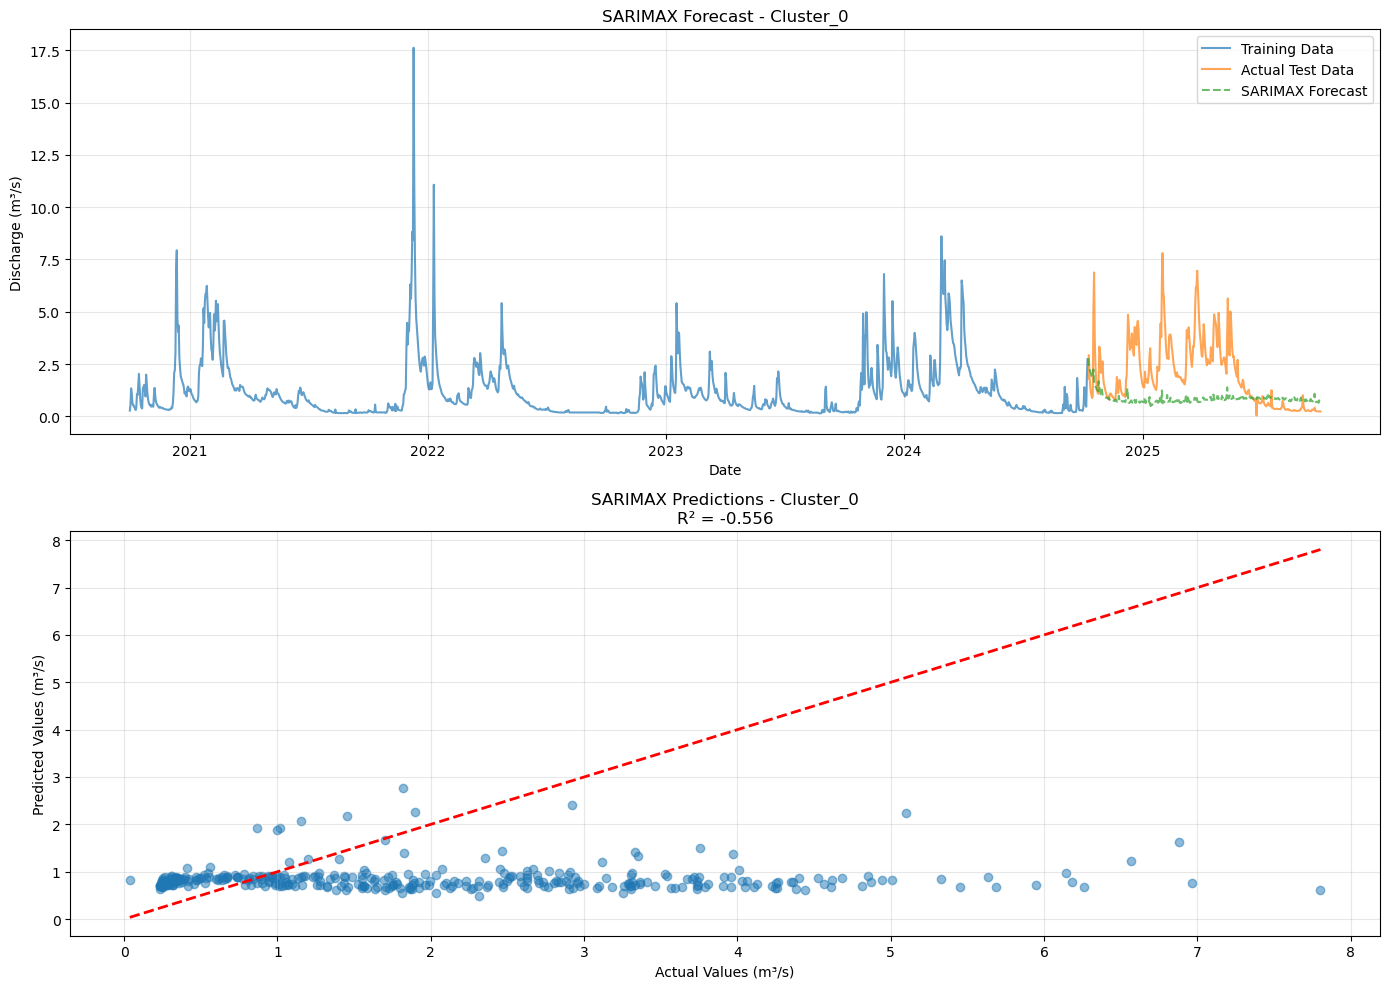


Cluster_1
Daily data points: 1777

ADF Statistic: -4.3529
p-value: 0.0004
  -> Series is STATIONARY

Training SARIMAX(1,0,1)...

Test Set Performance:
  RMSE: 0.0437
  MAE: 0.0287
  R²: -0.1953


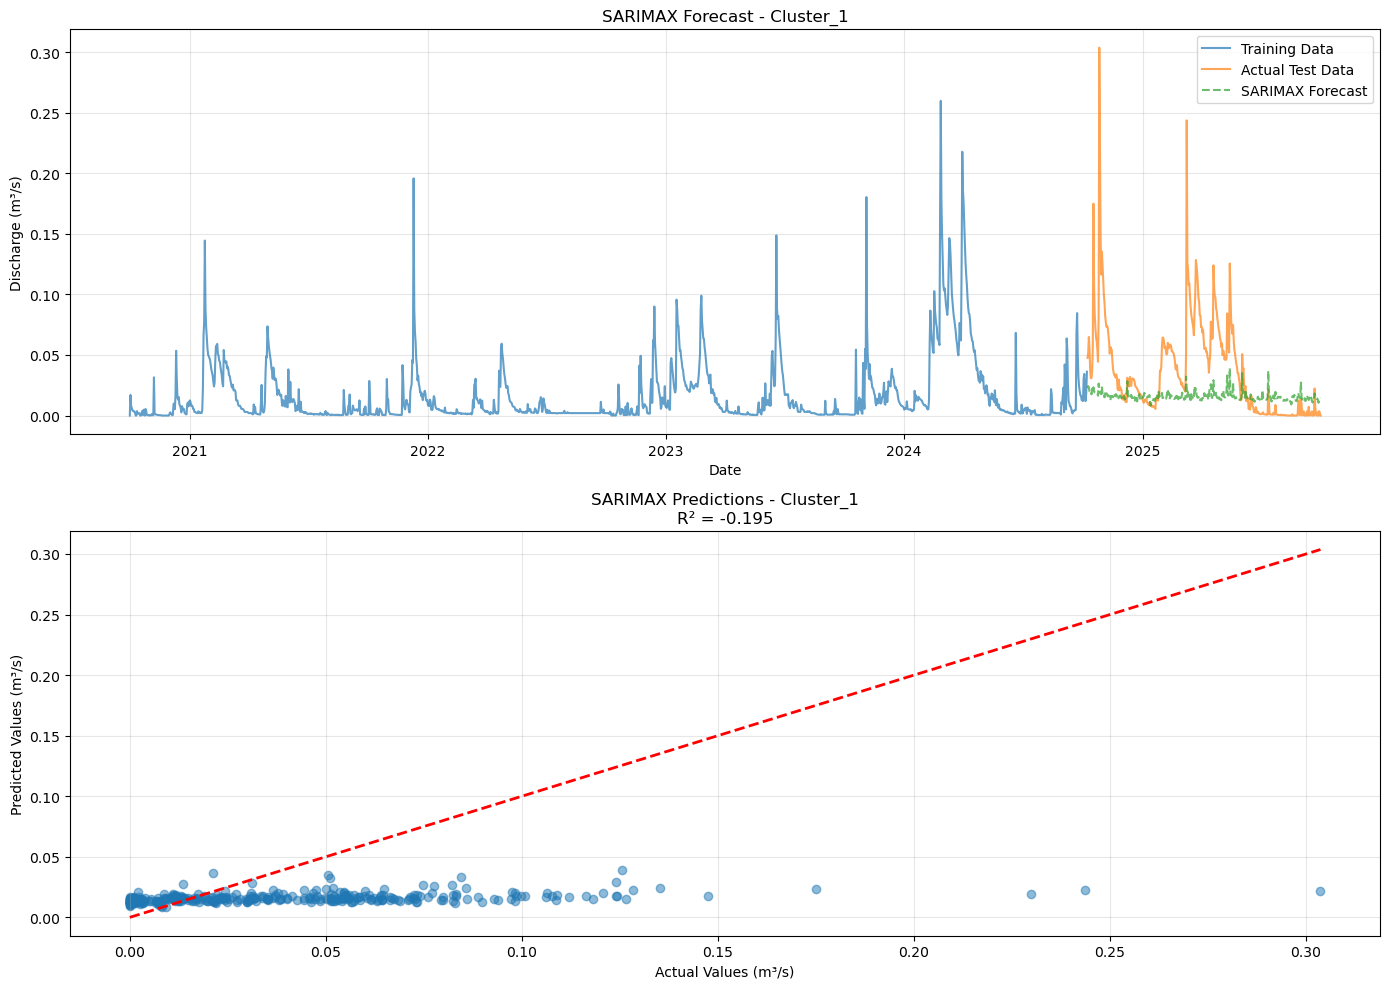


Cluster_2
Daily data points: 1778

ADF Statistic: -7.3112
p-value: 0.0000
  -> Series is STATIONARY

Training SARIMAX(1,0,1)...

Test Set Performance:
  RMSE: 3.3584
  MAE: 2.1561
  R²: 0.3492


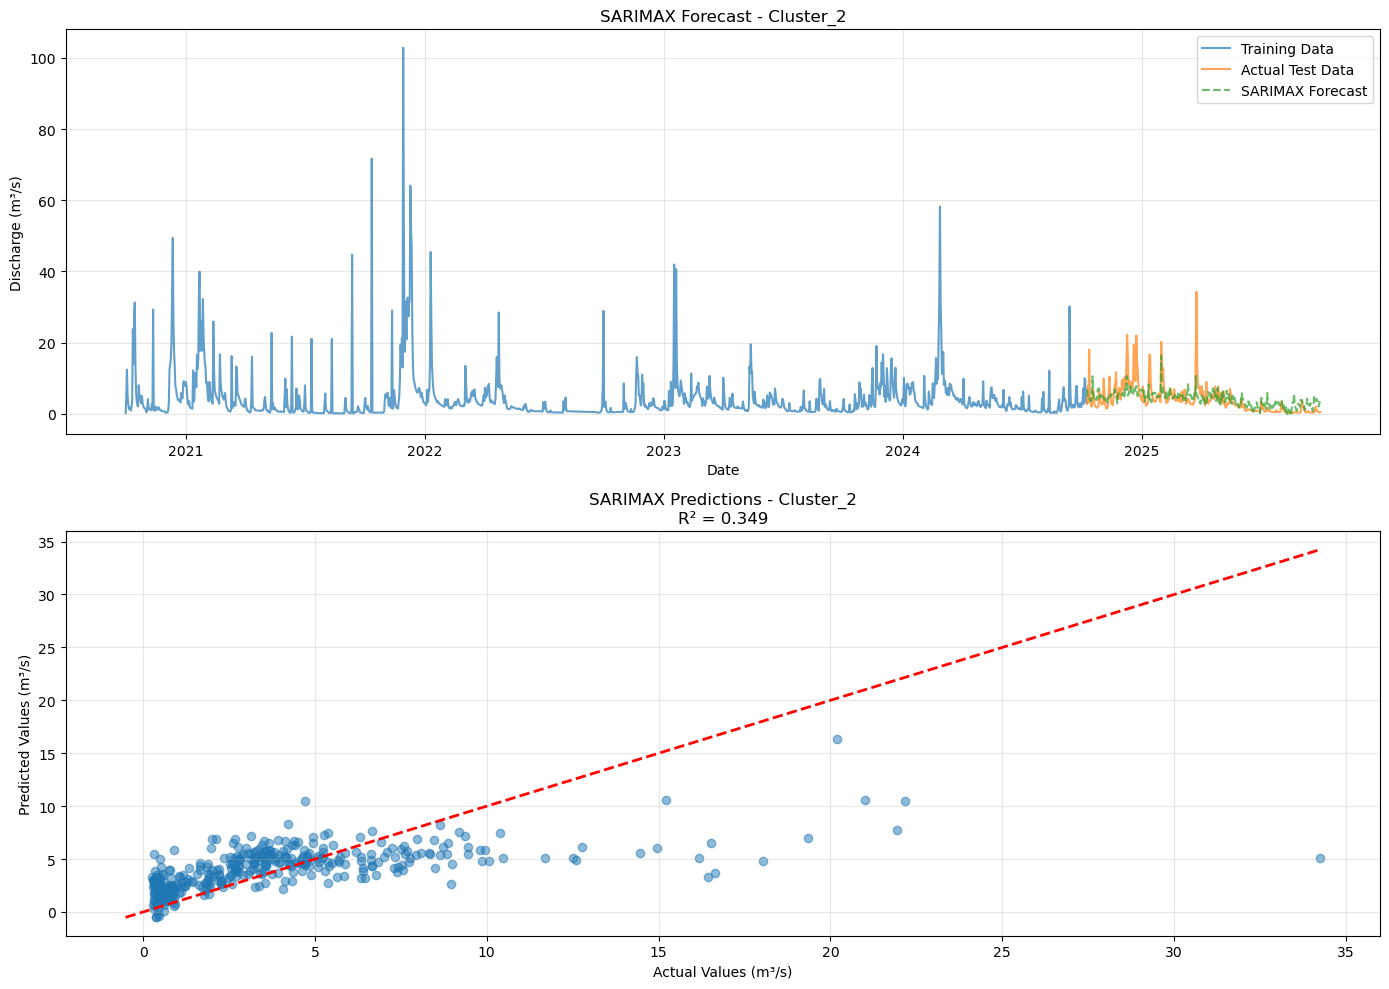


SARIMAX RESULTS SUMMARY


,Model,MSE,RMSE,MAE,R²
0,SARIMAX-Cluster_0 (Test),3.616564,1.901727,1.382815,-0.555878
1,SARIMAX-Cluster_1 (Test),0.001907,0.043666,0.028706,-0.195335
2,SARIMAX-Cluster_2 (Test),11.278754,3.358386,2.156144,0.349204


In [11]:
if not STATSMODELS_AVAILABLE:
    print("Statsmodels not available. Skipping ARIMA/SARIMAX models.")
    print("Install with: pip install statsmodels")
else:
    os.makedirs("4.1-results/arima", exist_ok=True)
    
    arima_results = []
    
    print("="*80)
    print("SARIMAX MODELS")
    print("="*80)
    
    # Use subset of most important features to avoid overfitting
    exog_features = ['P', 'soil_moisture', 'tav', 'Hrav', 'et0']
    
    for cluster_name, df in cluster_data.items():
        print(f"\n{'='*80}")
        print(f"{cluster_name}")
        print(f"{'='*80}")
        
        # Sort by date and aggregate to daily level (if needed)
        df_sorted = df.sort_values('Date').reset_index(drop=True)
        
        # Aggregate to daily (take mean of AM/PM readings)
        df_daily = df_sorted.groupby('Date').agg({
            target_col: 'mean',
            **{feat: 'mean' for feat in exog_features}
        }).reset_index()
        
        print(f"Daily data points: {len(df_daily)}")
        
        # Train/test split (80/20) - maintain temporal order
        split_idx = int(0.8 * len(df_daily))
        train_data = df_daily[:split_idx]
        test_data = df_daily[split_idx:]
        
        # Check stationarity
        adf_result = adfuller(train_data[target_col].dropna())
        print(f"\nADF Statistic: {adf_result[0]:.4f}")
        print(f"p-value: {adf_result[1]:.4f}")
        if adf_result[1] > 0.05:
            print("  -> Series is NON-STATIONARY (may need differencing)")
        else:
            print("  -> Series is STATIONARY")
        
        # Fit SARIMAX model
        # Parameters: (p,d,q) where d=1 for differencing if non-stationary
        d_order = 1 if adf_result[1] > 0.05 else 0
        
        print(f"\nTraining SARIMAX({1},{d_order},{1})...")
        
        try:
            model = SARIMAX(
                train_data[target_col],
                exog=train_data[exog_features],
                order=(1, d_order, 1),  # (p, d, q)
                enforce_stationarity=False,
                enforce_invertibility=False
            )
            
            fitted_model = model.fit(disp=False, maxiter=200)
            
            # Forecast on test set
            forecast = fitted_model.forecast(steps=len(test_data), exog=test_data[exog_features])
            
            # Evaluate
            test_metrics = evaluate_model(
                test_data[target_col].values,
                forecast.values,
                f"SARIMAX-{cluster_name} (Test)"
            )
            arima_results.append(test_metrics)
            
            print(f"\nTest Set Performance:")
            print(f"  RMSE: {test_metrics['RMSE']:.4f}")
            print(f"  MAE: {test_metrics['MAE']:.4f}")
            print(f"  R²: {test_metrics['R²']:.4f}")
            
            # Plot results
            fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))
            
            # Time series plot
            ax1.plot(train_data['Date'], train_data[target_col], label='Training Data', alpha=0.7)
            ax1.plot(test_data['Date'], test_data[target_col], label='Actual Test Data', alpha=0.7)
            ax1.plot(test_data['Date'], forecast.values, label='SARIMAX Forecast', linestyle='--', alpha=0.7)
            ax1.set_xlabel('Date')
            ax1.set_ylabel('Discharge (m³/s)')
            ax1.set_title(f'SARIMAX Forecast - {cluster_name}')
            ax1.legend()
            ax1.grid(True, alpha=0.3)
            
            # Scatter plot
            ax2.scatter(test_data[target_col].values, forecast.values, alpha=0.5)
            min_val = min(test_data[target_col].min(), forecast.min())
            max_val = max(test_data[target_col].max(), forecast.max())
            ax2.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2)
            ax2.set_xlabel('Actual Values (m³/s)')
            ax2.set_ylabel('Predicted Values (m³/s)')
            ax2.set_title(f'SARIMAX Predictions - {cluster_name}\nR² = {test_metrics["R²"]:.3f}')
            ax2.grid(True, alpha=0.3)
            
            plt.tight_layout()
            plt.savefig(f"4.1-results/arima/{cluster_name}_sarimax_results.png", dpi=300, bbox_inches='tight')
            plt.show()
            
        except Exception as e:
            print(f"Error fitting SARIMAX model: {e}")
            continue
    
    # Summary
    if arima_results:
        arima_results_df = pd.DataFrame(arima_results)
        print("\n" + "="*80)
        print("SARIMAX RESULTS SUMMARY")
        print("="*80)
        display(arima_results_df)

# Part 5: Model Comparison Across Clusters

OVERALL MODEL COMPARISON (Test Set)


,ModelType,Cluster,RMSE,MAE,R²
14,Random Forest,Cluster_2,5.517425,2.350773,0.649136
11,XGBoost,Cluster_1,0.019211,0.008900,0.647950
15,XGBoost,Cluster_2,5.858136,2.280281,0.604465
16,LightGBM,Cluster_2,5.919758,2.694113,0.596100
10,Random Forest,Cluster_1,0.021584,0.011413,0.555614
17,CatBoost,Cluster_2,6.330738,2.917641,0.538071
12,LightGBM,Cluster_1,0.022138,0.012384,0.532499
13,CatBoost,Cluster_1,0.023987,0.013851,0.451165
6,Random Forest,Cluster_0,1.979346,1.017915,0.427604
7,XGBoost,Cluster_0,2.072799,1.078173,0.372278



BEST MODEL PER CLUSTER

Cluster_0:
  Best Model: Random Forest
  R²: 0.4276
  RMSE: 1.9793
  MAE: 1.0179

Cluster_1:
  Best Model: XGBoost
  R²: 0.6480
  RMSE: 0.0192
  MAE: 0.0089

Cluster_2:
  Best Model: Random Forest
  R²: 0.6491
  RMSE: 5.5174
  MAE: 2.3508


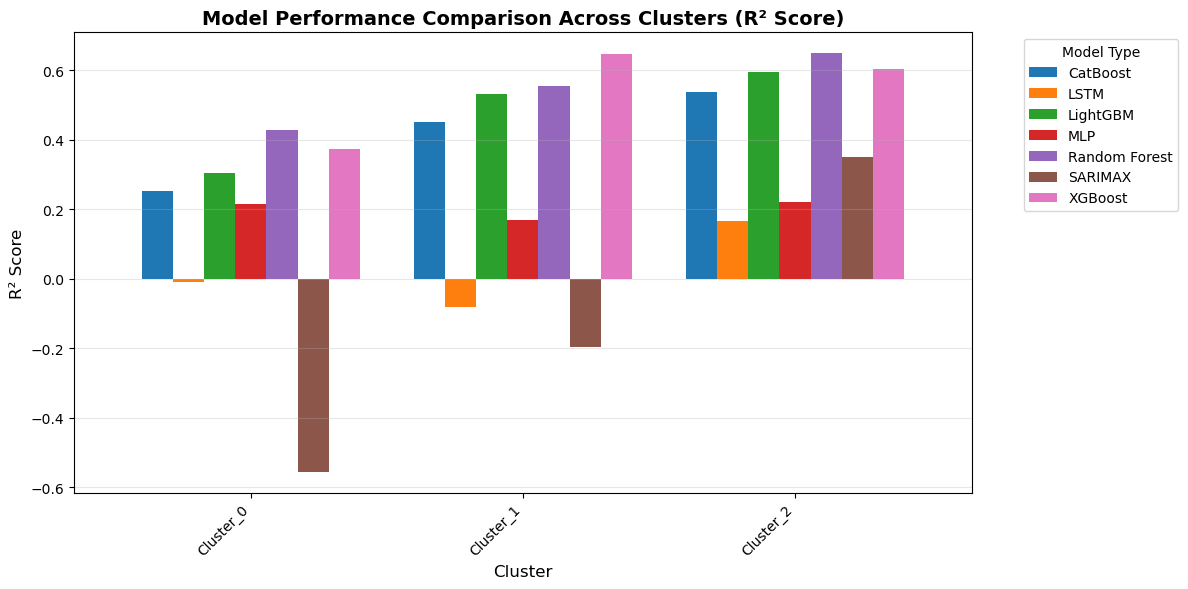

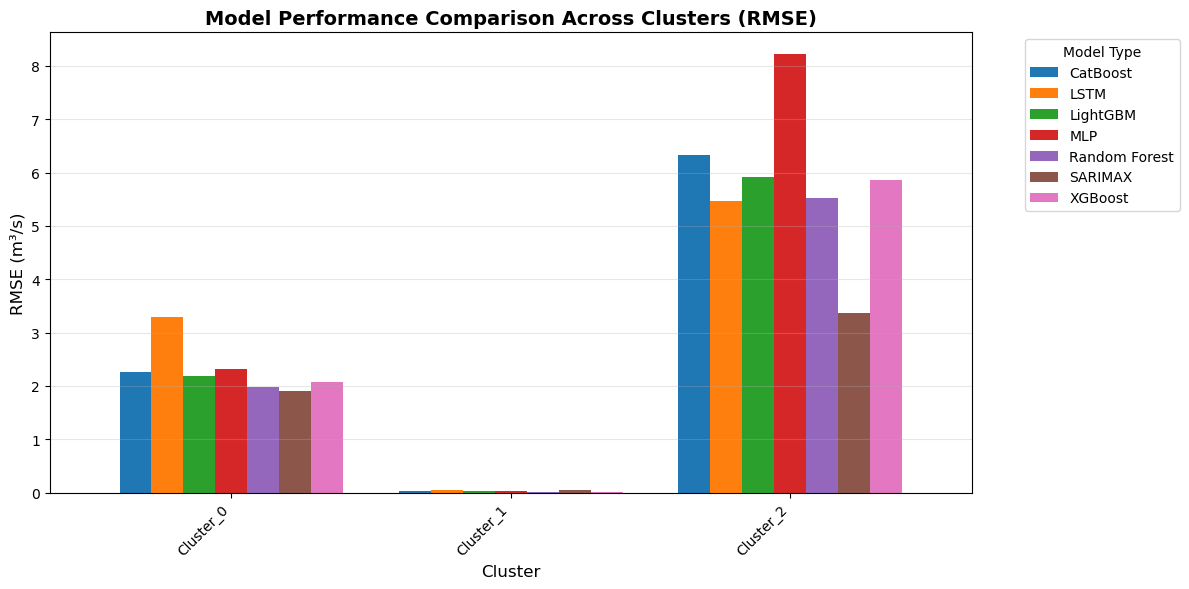


Results saved to: 4.1-results/comparison/all_model_results.csv


In [12]:
os.makedirs("4.1-results/comparison", exist_ok=True)

# Combine all results
all_results = []

if 'nn_results_df' in locals() and not nn_results_df.empty:
    all_results.append(nn_results_df)
if 'tree_results_df' in locals() and not tree_results_df.empty:
    all_results.append(tree_results_df)
if 'lstm_results_df' in locals() and not lstm_results_df.empty:
    all_results.append(lstm_results_df)
if 'arima_results_df' in locals() and not arima_results_df.empty:
    all_results.append(arima_results_df)

if all_results:
    combined_results = pd.concat(all_results, ignore_index=True)
    
    # Filter to test set only
    test_results = combined_results[combined_results['Model'].str.contains('Test')].copy()
    
    # Extract model type and cluster
    test_results['ModelType'] = test_results['Model'].str.extract(r'(.*?)-Cluster')[0]
    test_results['Cluster'] = test_results['Model'].str.extract(r'(Cluster_\d+)')[0]
    
    print("="*80)
    print("OVERALL MODEL COMPARISON (Test Set)")
    print("="*80)
    display(test_results[['ModelType', 'Cluster', 'RMSE', 'MAE', 'R²']].sort_values('R²', ascending=False))
    
    # Find best model for each cluster
    print("\n" + "="*80)
    print("BEST MODEL PER CLUSTER")
    print("="*80)
    
    for cluster in test_results['Cluster'].unique():
        cluster_results = test_results[test_results['Cluster'] == cluster]
        best_model = cluster_results.loc[cluster_results['R²'].idxmax()]
        print(f"\n{cluster}:")
        print(f"  Best Model: {best_model['ModelType']}")
        print(f"  R²: {best_model['R²']:.4f}")
        print(f"  RMSE: {best_model['RMSE']:.4f}")
        print(f"  MAE: {best_model['MAE']:.4f}")
    
    # Visualization: R² comparison
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Pivot for grouped bar chart
    pivot_data = test_results.pivot(index='Cluster', columns='ModelType', values='R²')
    pivot_data.plot(kind='bar', ax=ax, width=0.8)
    
    ax.set_title('Model Performance Comparison Across Clusters (R² Score)', fontsize=14, fontweight='bold')
    ax.set_xlabel('Cluster', fontsize=12)
    ax.set_ylabel('R² Score', fontsize=12)
    ax.legend(title='Model Type', bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    plt.savefig("4.1-results/comparison/model_comparison_r2.png", dpi=300, bbox_inches='tight')
    plt.show()
    
    # Visualization: RMSE comparison
    fig, ax = plt.subplots(figsize=(12, 6))
    
    pivot_rmse = test_results.pivot(index='Cluster', columns='ModelType', values='RMSE')
    pivot_rmse.plot(kind='bar', ax=ax, width=0.8)
    
    ax.set_title('Model Performance Comparison Across Clusters (RMSE)', fontsize=14, fontweight='bold')
    ax.set_xlabel('Cluster', fontsize=12)
    ax.set_ylabel('RMSE (m³/s)', fontsize=12)
    ax.legend(title='Model Type', bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    plt.savefig("4.1-results/comparison/model_comparison_rmse.png", dpi=300, bbox_inches='tight')
    plt.show()
    
    # Save results to CSV
    combined_results.to_csv("4.1-results/comparison/all_model_results.csv", index=False)
    print("\nResults saved to: 4.1-results/comparison/all_model_results.csv")
else:
    print("No results to compare. Please run the model training cells first.")

# Summary and Conclusions

## Key Findings:

This notebook implemented **cluster-based training** for discharge prediction using multiple advanced models:

### 1. Neural Networks (MLP)
- 3-layer architecture (100-50-25 neurons)
- Captures non-linear relationships between climate variables and discharge
- Benefits from feature scaling and early stopping

### 2. Advanced Tree Models
- **XGBoost**: Gradient boosting with regularization
- **LightGBM**: Efficient gradient boosting for large datasets
- **CatBoost**: Handles categorical features automatically
- Generally perform well without extensive feature engineering

### 3. LSTM Networks
- Captures temporal dependencies using past 7 days
- Particularly useful for sequential discharge patterns
- Requires careful sequence preparation and scaling

### 4. SARIMAX Models
- Classical time series approach with exogenous variables
- Incorporates climate features (P, soil_moisture, temperature, etc.)
- Provides interpretable forecasts with confidence intervals

## Cluster-Specific Insights:

Different clusters may benefit from different model types:
- **Cluster_0** (15 basins): Largest cluster, may benefit from complex models
- **Cluster_1** (1 basin - Bailín): Limited data, simpler models may work better
- **Cluster_2** (3 basins): Medium size, good for testing various approaches

## Next Steps:

1. **Hyperparameter Tuning**: Use grid search or Bayesian optimization
2. **Feature Engineering**: 
   - Add lag features (P_lag1, P_lag7, etc.)
   - Rolling statistics (7-day mean, std)
   - Seasonal indicators
3. **Ensemble Methods**: Combine predictions from multiple models
4. **Cross-Validation**: Implement time series cross-validation
5. **Seasonal Models**: Train separate models for different seasons
6. **Uncertainty Quantification**: Add prediction intervals